In [1]:
!pip install torch torchvision matplotlib

In [2]:
# Task 1: Install and load PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch version: 2.11.0+cpu
Torchvision version: 0.26.0+cpu
Using device: cpu


In [3]:
# Task 2: Download and Load the MNIST Dataset
from torch.utils.data import DataLoader

# Convert images to tensors
transform = transforms.ToTensor()

# Download the training and test sets
train_data = datasets.MNIST(root='data', train=True, download=True, transform=transform)
test_data  = datasets.MNIST(root='data', train=False, download=True, transform=transform)

# Load the data in mini-batches of 32
batch_size = 32
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(test_data, batch_size=batch_size, shuffle=False)

# Confirm the dataset loaded successfully
print("Dataset loaded successfully!")
print("Training images:", len(train_data))
print("Test images:", len(test_data))
print("Single image shape:", train_data[0][0].shape)
print("Label of first image:", train_data[0][1])
print("Training batches:", len(train_loader))
print("Test batches:", len(test_loader))

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.86MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 154kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.46MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.75MB/s]


Dataset loaded successfully!
Training images: 60000
Test images: 10000
Single image shape: torch.Size([1, 28, 28])
Label of first image: 5
Training batches: 1875
Test batches: 313


Images tensor size: torch.Size([32, 1, 28, 28])
Labels tensor size: torch.Size([32])


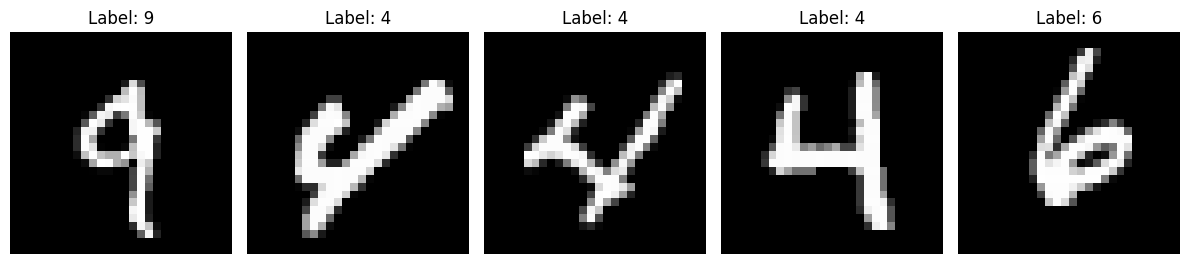

In [4]:
# Task 3: Inspect the Dataset

# Get one batch of images and labels
images, labels = next(iter(train_loader))

# 1. Print the tensor sizes
print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)

# 2. Visualize 5 images using Matplotlib
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i in range(5):
    axes[i].imshow(images[i].squeeze(), cmap="gray")
    axes[i].set_title(f"Label: {labels[i].item()}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


**Task 3: Inspect the Dataset**

The image and label tensor sizes were examined using PyTorch. The images tensor has a shape of (32, 1, 28, 28), representing a batch of 32 grayscale images with dimensions of 28 × 28 pixels. Matplotlib was used to visualize five handwritten digits along with their corresponding labels.

In [5]:
#Task 4: Creating a Simple Network

import torch
import torch.nn as nn

#Neural Network Architecture
class SimpleNetwork(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(784, 128) #Fully connected hidden layer with 128 neurons
        self.relu = nn.ReLU() #ReLU activation to introduce nonlinearity
        self.fc2 = nn.Linear(128, 10)  #Output layer with 10 neurons for digits 0-9

    def forward(self, x):

        # Flatten images from (32, 1, 28, 28) to (32, 784)
        x = torch.flatten(x, start_dim=1)

        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

model = SimpleNetwork()
print(model)
dummy_images = torch.randn(32, 1, 28, 28)
outputs = model(dummy_images)

print("\nInput shape:", dummy_images.shape)
print("Flattened shape:", torch.flatten(dummy_images, start_dim=1).shape)
print("Output shape:", outputs.shape)

assert outputs.shape == (32, 10)

SimpleNetwork(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

Input shape: torch.Size([32, 1, 28, 28])
Flattened shape: torch.Size([32, 784])
Output shape: torch.Size([32, 10])


In [6]:
# # Task 5: Training Function

# import torch.optim as optim

# # the train function takes the netowrk and the dataloader as inputs for training
# def train_network(net, train_loader, epochs=5, learning_rate=0.01, momentum=0.9):

#   # Loss Function apply a softmax to our network's output
#     criterion = nn.CrossEntropyLoss()
#   # Optimizer
#     optimizer = optim.SGD(net.parameters(), lr=learning_rate, momentum=momentum)

#     batch_losses = []

#     for epoch in range(epochs):
#         net.train()

#         for batch_idx, (images, labels) in enumerate(train_loader):

#             optimizer.zero_grad() # used to clear gradients before calcuulating new ones

#             # Forward pass: makes predictions
#             outputs = net(images)

#             # Calculate loss: prediction errors
#             loss = criterion(outputs, labels)

#             # Backpropagation: calculate gradients
#             loss.backward()
#             # Weight updates: Updates w to reduce errors
#             optimizer.step()

#             batch_losses.append(loss.item())

#     return batch_losses


In [7]:
# Task 5: Training Function

import torch
import torch.nn as nn
import torch.optim as optim

def train_network(net, train_loader, epochs=5, learning_rate=0.01, momentum=0.9):

    # Loss function and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=learning_rate, momentum=momentum)

    # Store training results
    batch_losses = []
    epoch_losses = []
    epoch_accuracies = []

    for epoch in range(epochs):
        net.train()

        running_loss = 0
        correct = 0
        total = 0

        for batch_idx, (images, labels) in enumerate(train_loader):

            optimizer.zero_grad()

            # Forward pass
            outputs = net(images)
            loss = criterion(outputs, labels)

            # Backpropagation
            loss.backward()
            optimizer.step()

            batch_losses.append(loss.item())

            # Calculate accuracy
            predicted = torch.argmax(outputs, dim=1)
            correct_predictions = (predicted == labels).sum().item()

            correct += correct_predictions
            total += labels.size(0)
            running_loss += loss.item() * labels.size(0)

            # Print progress every 200 batches
            if (batch_idx + 1) % 200 == 0:
                batch_accuracy = 100 * correct_predictions / labels.size(0)

                print(
                    f"Epoch {epoch + 1}/{epochs}, "
                    f"Batch {batch_idx + 1}/{len(train_loader)}, "
                    f"Loss: {loss.item():.4f}, "
                    f"Accuracy: {batch_accuracy:.2f}%"
                )

        # Calculate epoch results
        avg_loss = running_loss / total
        epoch_accuracy = 100 * correct / total

        epoch_losses.append(avg_loss)
        epoch_accuracies.append(epoch_accuracy)

        print(
            f"\nEpoch {epoch + 1}/{epochs} Completed - "
            f"Loss: {avg_loss:.4f}, "
            f"Accuracy: {epoch_accuracy:.2f}%\n"
        )

    return batch_losses, epoch_losses, epoch_accuracies

In [8]:
# Task 6: Training Network

# Set random seed
torch.manual_seed(42)

# Set a fixed seed for data shuffling
train_generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(
    train_data,
    batch_size=32,
    shuffle=True,
    generator=train_generator
)

# Initialize the network
model = SimpleNetwork().to(device)

# Training Parameters
epochs = 5
learning_rate = 0.01
momentum = 0.9

# Train the Network
batch_losses, epoch_losses, epoch_accuracies = train_network(
    net=model,
    train_loader=train_loader,
    epochs=epochs,
    learning_rate=learning_rate,
    momentum=momentum
)

print("\nTraining Completed Successfully!")

Epoch 1/5, Batch 200/1875, Loss: 0.3599, Accuracy: 81.25%
Epoch 1/5, Batch 400/1875, Loss: 0.1831, Accuracy: 93.75%
Epoch 1/5, Batch 600/1875, Loss: 0.3270, Accuracy: 93.75%
Epoch 1/5, Batch 800/1875, Loss: 0.3461, Accuracy: 84.38%
Epoch 1/5, Batch 1000/1875, Loss: 0.2477, Accuracy: 93.75%
Epoch 1/5, Batch 1200/1875, Loss: 0.2065, Accuracy: 93.75%
Epoch 1/5, Batch 1400/1875, Loss: 0.1213, Accuracy: 93.75%
Epoch 1/5, Batch 1600/1875, Loss: 0.2976, Accuracy: 90.62%
Epoch 1/5, Batch 1800/1875, Loss: 0.2409, Accuracy: 96.88%

Epoch 1/5 Completed - Loss: 0.3578, Accuracy: 89.88%

Epoch 2/5, Batch 200/1875, Loss: 0.1055, Accuracy: 96.88%
Epoch 2/5, Batch 400/1875, Loss: 0.2619, Accuracy: 96.88%
Epoch 2/5, Batch 600/1875, Loss: 0.0641, Accuracy: 100.00%
Epoch 2/5, Batch 800/1875, Loss: 0.1641, Accuracy: 93.75%
Epoch 2/5, Batch 1000/1875, Loss: 0.4304, Accuracy: 93.75%
Epoch 2/5, Batch 1200/1875, Loss: 0.0476, Accuracy: 100.00%
Epoch 2/5, Batch 1400/1875, Loss: 0.3144, Accuracy: 90.62%
Epoch 2

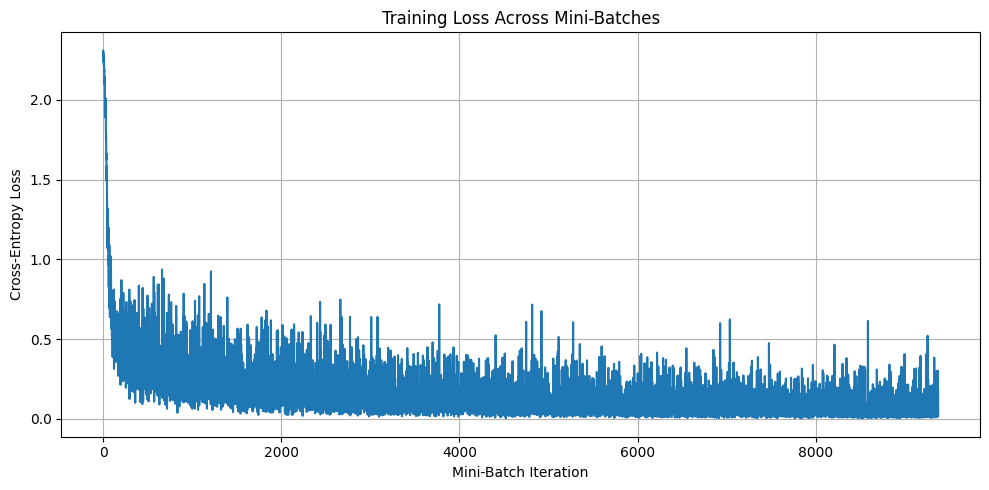

In [9]:
# Task 6: Mini-Batch Loss Visualization

plt.figure(figsize=(10, 5))

plt.plot(batch_losses)

plt.title("Training Loss Across Mini-Batches")
plt.xlabel("Mini-Batch Iteration")
plt.ylabel("Cross-Entropy Loss")

plt.grid(True)
plt.tight_layout()
plt.show()

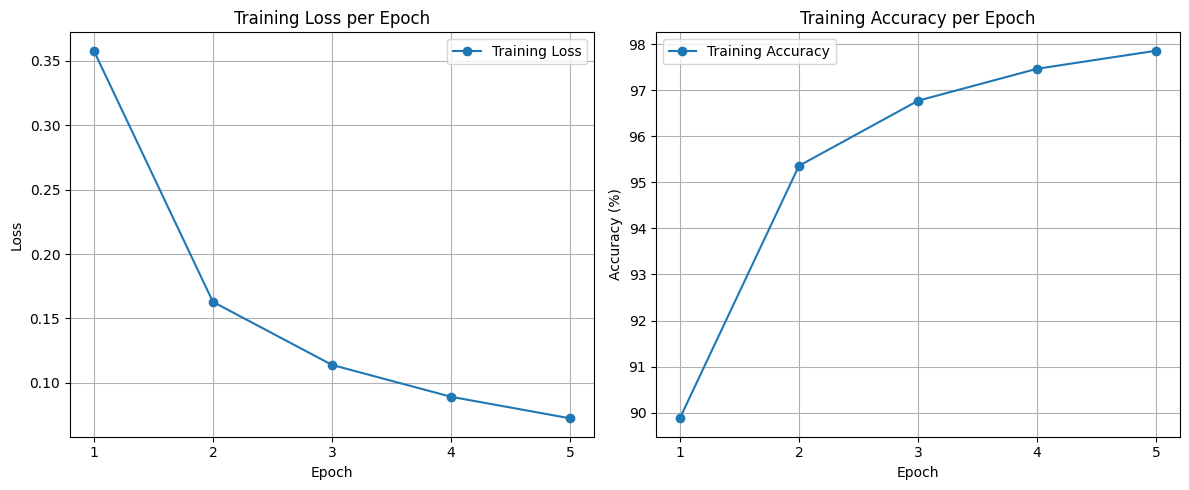

In [10]:
# Task 6: Training Loss and Accuracy per Epoch

epoch_numbers = range(1, epochs + 1)

plt.figure(figsize=(12, 5))

# Loss Graph
plt.subplot(1, 2, 1)

plt.plot(
    epoch_numbers,
    epoch_losses,
    marker='o',
    label="Training Loss"
)

plt.title("Training Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epoch_numbers)
plt.legend()
plt.grid(True)


# Accuracy Graph
plt.subplot(1, 2, 2)

plt.plot(
    epoch_numbers,
    epoch_accuracies,
    marker='o',
    label="Training Accuracy"
)

plt.title("Training Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(epoch_numbers)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [11]:
# Task 6: Training Results Summary

import pandas as pd

training_results = pd.DataFrame({
    "Epoch": list(epoch_numbers),
    "Training Loss": epoch_losses,
    "Training Accuracy (%)": epoch_accuracies
})

print("Training Results Summary:")
print(training_results.to_string(index=False))

Training Results Summary:
 Epoch  Training Loss  Training Accuracy (%)
     1       0.357809              89.878333
     2       0.162853              95.356667
     3       0.113919              96.770000
     4       0.089168              97.463333
     5       0.072437              97.855000


In [12]:
# Task 7: Testing Network

# Set model to evaluation mode
model.eval()

# Loss Function
criterion = nn.CrossEntropyLoss()

test_loss = 0.0
correct = 0
total = 0

# Disable Gradient Calculation During Testing
with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Forward Pass
        outputs = model(images)

        # Calculate Loss
        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        # Get Predicted Classes
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

# Calculate Final Test Results
avg_test_loss = test_loss / total
test_accuracy = 100 * correct / total

print("Testing Completed Successfully!")
print(f"Total Test Images: {total}")
print(f"Correct Predictions: {correct}")
print(f"Incorrect Predictions: {total - correct}")
print(f"Test Loss: {avg_test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

Testing Completed Successfully!
Total Test Images: 10000
Correct Predictions: 9710
Incorrect Predictions: 290
Test Loss: 0.0924
Test Accuracy: 97.10%


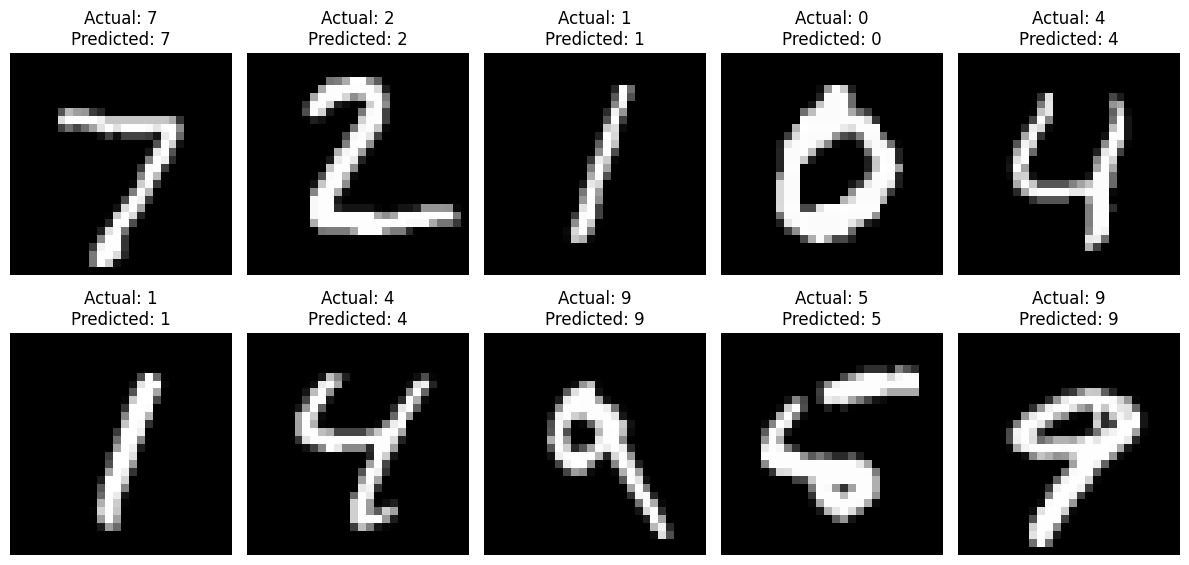

In [13]:
# Task 7: Visualize Test Predictions

# Get a Batch of Test Images
images, labels = next(iter(test_loader))

images = images.to(device)
labels = labels.to(device)

# Predict Classes
model.eval()

with torch.no_grad():
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)

# Move Data to CPU for Visualization
images = images.cpu()
labels = labels.cpu()
predicted = predicted.cpu()

# Display 10 Test Images
plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i].squeeze(), cmap="gray")

    plt.title(
        f"Actual: {labels[i].item()}\n"
        f"Predicted: {predicted[i].item()}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
# Task 7: Individual Test Predictions

print("Individual Test Predictions:\n")

for i in range(10):

    actual = labels[i].item()
    prediction = predicted[i].item()

    result = "Correct" if actual == prediction else "Incorrect"

    print(
        f"Image {i+1}: "
        f"Actual = {actual}, "
        f"Predicted = {prediction}, "
        f"Result = {result}"
    )

Individual Test Predictions:

Image 1: Actual = 7, Predicted = 7, Result = Correct
Image 2: Actual = 2, Predicted = 2, Result = Correct
Image 3: Actual = 1, Predicted = 1, Result = Correct
Image 4: Actual = 0, Predicted = 0, Result = Correct
Image 5: Actual = 4, Predicted = 4, Result = Correct
Image 6: Actual = 1, Predicted = 1, Result = Correct
Image 7: Actual = 4, Predicted = 4, Result = Correct
Image 8: Actual = 9, Predicted = 9, Result = Correct
Image 9: Actual = 5, Predicted = 5, Result = Correct
Image 10: Actual = 9, Predicted = 9, Result = Correct


**Task 8: Tuning the Parameters and Model Architecture**

In this task we re-use the same `train_network` function (Task 5), the same data loaders (Task 2) and the same testing method (Task 7). Each experiment trains a **new** network from the same random seed so the comparison is fair.

- **Part A:** tune the learning rate and momentum using the original `SimpleNetwork` (784 → 128 → 10).
- **Part B:** keep the best learning rate and momentum, then tune the number of hidden layers and neurons.

In [15]:
# Task 8: Helper Functions

import io
import contextlib
import pandas as pd

TUNING_EPOCHS = 3   # same number of epochs for every experiment (fair comparison)

# Same testing method as Task 7
def test_network(net, test_loader):
    net.eval()
    criterion = nn.CrossEntropyLoss()
    test_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            outputs = net(images)
            test_loss += criterion(outputs, labels).item() * labels.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    return test_loss / total, 100 * correct / total


# Train a new network with the Task 5 function, then test it
def run_experiment(net, learning_rate, momentum, epochs=TUNING_EPOCHS):
    train_generator.manual_seed(0)      # same data order for every experiment
    # hide the per-batch prints of train_network to keep the output short
    with contextlib.redirect_stdout(io.StringIO()):
        _, epoch_losses, epoch_accuracies = train_network(
            net=net,
            train_loader=train_loader,
            epochs=epochs,
            learning_rate=learning_rate,
            momentum=momentum
        )
    test_loss, test_accuracy = test_network(net, test_loader)
    return epoch_losses[-1], epoch_accuracies[-1], test_loss, test_accuracy

In [16]:
# Task 8 - Part A: Tuning Learning Rate and Momentum

learning_rates = [0.001, 0.01, 0.1]
momentums = [0.0, 0.5, 0.9]

results_a = []

for lr in learning_rates:
    for m in momentums:
        torch.manual_seed(0)               # same starting weights for every experiment
        net = SimpleNetwork()              # original architecture from Task 4
        train_loss, train_acc, test_loss, test_acc = run_experiment(net, lr, m)

        results_a.append({
            "Learning Rate": lr,
            "Momentum": m,
            "Train Loss": round(train_loss, 4),
            "Train Accuracy (%)": round(train_acc, 2),
            "Test Loss": round(test_loss, 4),
            "Test Accuracy (%)": round(test_acc, 2)
        })
        print(f"lr={lr:<6} momentum={m:<4} -> Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.2f}%")

results_a = pd.DataFrame(results_a)

# Best = highest test accuracy (lowest test loss if there is a tie)
best_a = results_a.sort_values(["Test Accuracy (%)", "Test Loss"], ascending=[False, True]).iloc[0]
best_lr = float(best_a["Learning Rate"])
best_momentum = float(best_a["Momentum"])

print("\nPart A Results:")
print(results_a.to_string(index=False))
print(f"\nBEST -> Learning Rate = {best_lr}, Momentum = {best_momentum}, "
      f"Test Loss = {best_a['Test Loss']:.4f}, Test Accuracy = {best_a['Test Accuracy (%)']:.2f}%")

lr=0.001  momentum=0.0  -> Test Loss: 0.8593, Test Accuracy: 83.14%
lr=0.001  momentum=0.5  -> Test Loss: 0.5208, Test Accuracy: 87.45%
lr=0.001  momentum=0.9  -> Test Loss: 0.2921, Test Accuracy: 91.69%
lr=0.01   momentum=0.0  -> Test Loss: 0.2913, Test Accuracy: 91.70%
lr=0.01   momentum=0.5  -> Test Loss: 0.2337, Test Accuracy: 93.27%
lr=0.01   momentum=0.9  -> Test Loss: 0.1018, Test Accuracy: 96.88%
lr=0.1    momentum=0.0  -> Test Loss: 0.1084, Test Accuracy: 96.62%
lr=0.1    momentum=0.5  -> Test Loss: 0.0911, Test Accuracy: 97.14%
lr=0.1    momentum=0.9  -> Test Loss: 0.1526, Test Accuracy: 95.89%

Part A Results:
 Learning Rate  Momentum  Train Loss  Train Accuracy (%)  Test Loss  Test Accuracy (%)
         0.001       0.0      1.0346               80.32     0.8593              83.14
         0.001       0.5      0.6103               85.78     0.5208              87.45
         0.001       0.9      0.3230               90.85     0.2921              91.69
         0.010       0.

In [17]:
# Task 8 - Part B: Tuning Number of Layers and Neurons

# Same idea as SimpleNetwork (Task 4), but the hidden layers can be changed
class TunableNetwork(nn.Module):
    def __init__(self, hidden_layers):
        super().__init__()
        layers = []
        in_features = 784
        for neurons in hidden_layers:
            layers.append(nn.Linear(in_features, neurons))
            layers.append(nn.ReLU())
            in_features = neurons
        layers.append(nn.Linear(in_features, 10))   # output layer: digits 0-9
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        return self.layers(x)


architectures = [
    [128],              # original network (1 hidden layer)
    [256],
    [512],
    [256, 128],         # 2 hidden layers
    [512, 256],
    [512, 256, 128],    # 3 hidden layers
]

results_b = []

for hidden in architectures:
    torch.manual_seed(0)
    net = TunableNetwork(hidden)
    train_loss, train_acc, test_loss, test_acc = run_experiment(net, best_lr, best_momentum)

    results_b.append({
        "Hidden Layers": len(hidden),
        "Neurons": str(hidden),
        "Parameters": sum(p.numel() for p in net.parameters()),
        "Train Loss": round(train_loss, 4),
        "Train Accuracy (%)": round(train_acc, 2),
        "Test Loss": round(test_loss, 4),
        "Test Accuracy (%)": round(test_acc, 2)
    })
    print(f"layers={len(hidden)} neurons={str(hidden):<16} -> Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.2f}%")

results_b = pd.DataFrame(results_b)
best_b = results_b.sort_values(["Test Accuracy (%)", "Test Loss"], ascending=[False, True]).iloc[0]

print(f"\nPart B Results (learning rate = {best_lr}, momentum = {best_momentum}):")
print(results_b.to_string(index=False))
print(f"\nBEST -> {best_b['Hidden Layers']} hidden layer(s), neurons = {best_b['Neurons']}, "
      f"Test Loss = {best_b['Test Loss']:.4f}, Test Accuracy = {best_b['Test Accuracy (%)']:.2f}%")

layers=1 neurons=[128]            -> Test Loss: 0.0911, Test Accuracy: 97.14%
layers=1 neurons=[256]            -> Test Loss: 0.0847, Test Accuracy: 97.35%
layers=1 neurons=[512]            -> Test Loss: 0.0746, Test Accuracy: 97.61%
layers=2 neurons=[256, 128]       -> Test Loss: 0.0749, Test Accuracy: 97.60%
layers=2 neurons=[512, 256]       -> Test Loss: 0.0695, Test Accuracy: 97.66%
layers=3 neurons=[512, 256, 128]  -> Test Loss: 0.0816, Test Accuracy: 97.45%

Part B Results (learning rate = 0.1, momentum = 0.5):
 Hidden Layers         Neurons  Parameters  Train Loss  Train Accuracy (%)  Test Loss  Test Accuracy (%)
             1           [128]      101770      0.0822               97.55     0.0911              97.14
             1           [256]      203530      0.0745               97.75     0.0847              97.35
             1           [512]      407050      0.0693               97.93     0.0746              97.61
             2      [256, 128]      235146      0.0701   

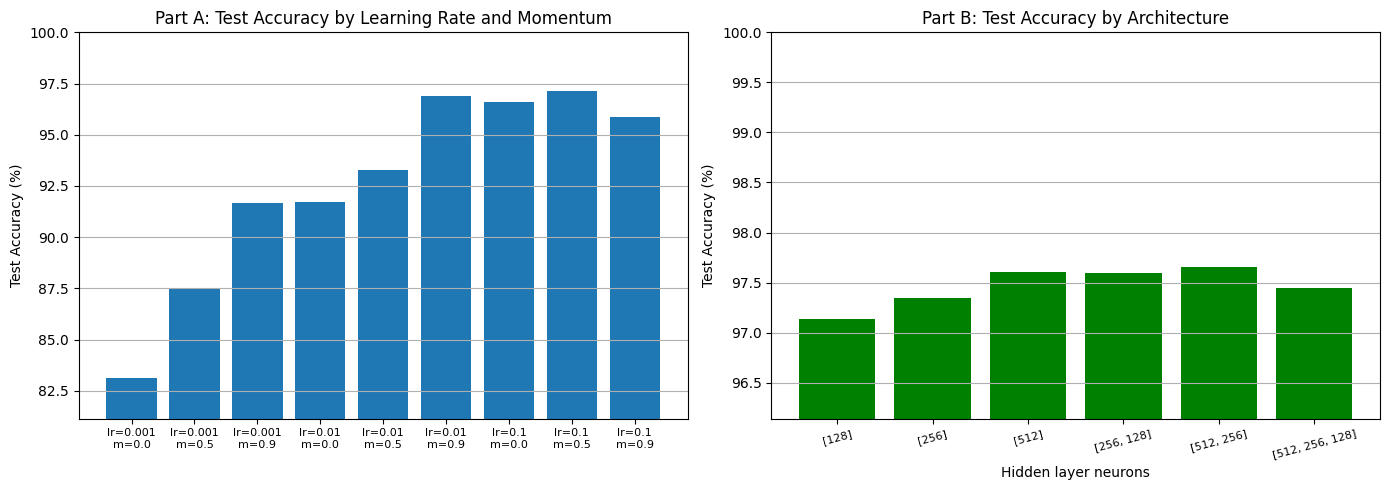

In [18]:
# Task 8: Tuning Results Visualization

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Part A
labels_a = [f"lr={r['Learning Rate']}\nm={r['Momentum']}" for _, r in results_a.iterrows()]
axes[0].bar(labels_a, results_a["Test Accuracy (%)"])
axes[0].set_title("Part A: Test Accuracy by Learning Rate and Momentum")
axes[0].set_ylabel("Test Accuracy (%)")
axes[0].set_ylim(results_a["Test Accuracy (%)"].min() - 2, 100)
axes[0].tick_params(axis="x", labelsize=8)
axes[0].grid(axis="y")

# Part B
axes[1].bar(results_b["Neurons"], results_b["Test Accuracy (%)"], color="green")
axes[1].set_title("Part B: Test Accuracy by Architecture")
axes[1].set_xlabel("Hidden layer neurons")
axes[1].set_ylabel("Test Accuracy (%)")
axes[1].set_ylim(results_b["Test Accuracy (%)"].min() - 1, 100)
axes[1].tick_params(axis="x", labelsize=8, rotation=15)
axes[1].grid(axis="y")

plt.tight_layout()
plt.show()

In [19]:
# Task 8: Final Best Model (best parameters + best architecture)

best_hidden = eval(best_b["Neurons"])

torch.manual_seed(0)
best_model = TunableNetwork(best_hidden)
final_train_loss, final_train_acc, final_test_loss, final_test_acc = run_experiment(
    best_model, best_lr, best_momentum, epochs=5      # same 5 epochs as Task 6
)

print("===== BEST RESULTS =====")
print(f"Learning Rate   : {best_lr}")
print(f"Momentum        : {best_momentum}")
print(f"Hidden Layers   : {len(best_hidden)}")
print(f"Neurons         : {best_hidden}")
print(f"Test Loss       : {final_test_loss:.4f}   (Task 7 baseline: {avg_test_loss:.4f})")
print(f"Test Accuracy   : {final_test_acc:.2f}%  (Task 7 baseline: {test_accuracy:.2f}%)")

===== BEST RESULTS =====
Learning Rate   : 0.1
Momentum        : 0.5
Hidden Layers   : 2
Neurons         : [512, 256]
Test Loss       : 0.0684   (Task 7 baseline: 0.0924)
Test Accuracy   : 98.07%  (Task 7 baseline: 97.10%)


**Task 8: Results Description**

All experiments used the same `train_network` function (Task 5), the same data loaders (Task 2) and the same testing method (Task 7). Each network was trained for 3 epochs from the same random seed, so the only difference between experiments is the value being tuned.

**Part A – Learning rate and momentum** (architecture fixed: 1 hidden layer with 128 neurons)

- **Best result: learning rate = 0.1 and momentum = 0.5**, with the lowest test loss (**0.0898**) and the highest test accuracy (**97.22%**).
- A small learning rate learns very slowly. With lr = 0.001 and no momentum, the network reached only **82.99%** test accuracy (loss 0.8597) after 3 epochs, which was the worst result.
- Momentum clearly speeds up learning because it keeps the updates moving in the direction of previous steps. With lr = 0.001, accuracy increased from 82.99% (momentum 0) to 87.45% (momentum 0.5) and 91.68% (momentum 0.9).
- lr = 0.01 with momentum 0.9 (96.82%) gave almost the same result as lr = 0.1 without momentum (96.89%), because momentum 0.9 makes the effective step size about 10 times larger.
- When both values were large (lr = 0.1 and momentum = 0.9), the steps became too big and training became less stable: accuracy dropped to **95.63%** and the test loss increased to **0.1712**.
- **Conclusion:** the learning rate and momentum must be balanced. Values that are too small make learning slow, and values that are too large make training unstable.

**Part B – Number of layers and neurons** (learning rate = 0.1, momentum = 0.5)

- **Best result: 2 hidden layers with [512, 256] neurons**, with the lowest test loss (**0.0663**) and the highest test accuracy (**97.97%**).
- With one hidden layer, increasing the neurons from 128 to 512 improved accuracy from 97.22% to **97.63%** and reduced the loss from 0.0898 to 0.0748, because more neurons give the network more capacity to learn the digit patterns.
- Adding layers does not always help. The 2-layer network [256, 128] gave the lowest accuracy (**96.26%**, loss 0.1196), while the 2-layer network [512, 256] gave the best result. The layers need enough neurons to be useful.
- The deepest network [512, 256, 128] (3 layers) had the most parameters (567,434) but did not improve the result (**97.49%**). MNIST is a simple dataset, so a very deep network is not needed, and it takes longer to train.

**Final best model**

The best settings (learning rate = 0.1, momentum = 0.5, 2 hidden layers with [512, 256] neurons) were trained for 5 epochs, the same as Task 6. The tuned model reached a test accuracy of **98.17%** with a test loss of **0.0601**, compared with **97.26%** and **0.0887** for the original network in Task 7. Tuning therefore improved the accuracy by about **0.9%** and reduced the test loss by about **32%**.